# Mineração de Dados — Classificação de estudantes em risco de evasão

**Projeto Interdisciplinar — 6º semestre DSM — Fatec Franca**
Componente: `backend-MD`
Autores: Guilherme Luís Rodrigues Silva e Miguel Angelo Silva

Este notebook percorre as nove etapas do processo de Mineração de Dados do projeto, na mesma ordem em que elas aparecem no relatório do fluxo e no contexto do `backend-MD`:

1. Entendimento do problema
2. Entendimento dos dados
3. Preparação
4. Transformação
5. Seleção de atributos
6. Treinamento
7. Avaliação
8. Interpretação
9. Disponibilização

O código não reimplementa o pipeline: ele importa `config.py`, `prepare_data.py` e `train_model.py` e chama as mesmas funções que geram o modelo em produção (mesmas features, mesma semente, mesma divisão, mesmos candidatos e mesma regra de escolha). O notebook **não grava nada** em `artifacts/`; o modelo servido pela API continua sendo gerado por `npm run ml:pipeline`.

> Para executar: ambiente do `environment.yml` (conda) ou o `ML/.venv` com `pip install matplotlib==3.9.2 seaborn==0.13.2 jupyter`, abrindo o notebook com `ML/` como pasta de trabalho. A etapa 9 usa os artefatos gerados pelo pipeline; sem eles, essa etapa avisa e é pulada.

## 1. Entendimento do problema

Instituições de ensino e de apoio social precisam identificar cedo os estudantes que correm risco de abandonar o curso, para priorizar quem recebe acompanhamento. A tarefa escolhida é **classificação supervisionada**: a partir dos dados do estudante, prever em qual de três situações ele se encaixa.

| Classe | Situação |
| --- | --- |
| `Dropout` | evadiu |
| `Enrolled` | ainda matriculado |
| `Graduate` | formado |

Os erros não custam o mesmo. Deixar de sinalizar um estudante que vai evadir é o erro mais caro, porque ele fica sem acompanhamento. Por isso a **revocação da classe `Dropout`** (a proporção dos evasores reais que o modelo encontra) entra na escolha do modelo com o mesmo peso do F1 macro.

O resultado é apoio à decisão, não uma previsão garantida. A classificação vai para o `backend-Project`, que a transforma em prioridade de acompanhamento e a mostra na Web e no Mobile.

## 2. Entendimento dos dados

A base é a Predict Students' Dropout and Academic Success, do UCI Machine Learning Repository (https://archive.ics.uci.edu/dataset/697/predict+students+dropout+and+academic+success), com estudantes de uma instituição de ensino superior portuguesa. No projeto o arquivo canônico é `ML/predic-students-dataset.csv`: separador `;` e UTF-8 com BOM.

In [1]:
import json
import subprocess
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config as cfg
import prepare_data as prep
import train_model as tm

tabela = pd.read_csv(cfg.RAW_DATASET, sep=cfg.CSV_SEPARATOR, encoding=cfg.CSV_ENCODING)
tabela.columns = cfg.normalize_csv_columns(tabela.columns)
tabela.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [2]:
tabela.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4424 entries, 0 to 4423
Data columns (total 37 columns):
 #   Column                                          Non-Null Count  Dtype  
---  ------                                          --------------  -----  
 0   Marital status                                  4424 non-null   int64  
 1   Application mode                                4424 non-null   int64  
 2   Application order                               4424 non-null   int64  
 3   Course                                          4424 non-null   int64  
 4   Daytime/evening attendance                      4424 non-null   int64  
 5   Previous qualification                          4424 non-null   int64  
 6   Previous qualification (grade)                  4424 non-null   float64
 7   Nacionality                                     4424 non-null   int64  
 8   Mother's qualification                          4424 non-null   int64  
 9   Father's qualification                   

In [3]:
tabela.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Marital status,4424.0,1.18,0.61,1.00,1.00,1.00,1.00,6.00
Application mode,4424.0,18.67,17.48,1.00,1.00,17.00,39.00,57.00
Application order,4424.0,1.73,1.31,0.00,1.00,1.00,2.00,9.00
Course,4424.0,8856.64,2063.57,33.00,9085.00,9238.00,9556.00,9991.00
Daytime/evening attendance,4424.0,0.89,0.31,0.00,1.00,1.00,1.00,1.00
Previous qualification,4424.0,4.58,10.22,1.00,1.00,1.00,1.00,43.00
Previous qualification (grade),4424.0,132.61,13.19,95.00,125.00,133.10,140.00,190.00
Nacionality,4424.0,1.87,6.91,1.00,1.00,1.00,1.00,109.00
Mother's qualification,4424.0,19.56,15.60,1.00,2.00,19.00,37.00,44.00
Father's qualification,4424.0,22.28,15.34,1.00,3.00,19.00,37.00,44.00


In [4]:
print("valores nulos no total:", int(tabela.isnull().sum().sum()))
print("linhas duplicadas:", int(tabela.duplicated().sum()))

valores nulos no total: 0
linhas duplicadas: 0


          estudantes  proporcao_%
Target                           
Dropout         1421         32.1
Enrolled         794         17.9
Graduate        2209         49.9

razão entre a maior e a menor classe: 2.78


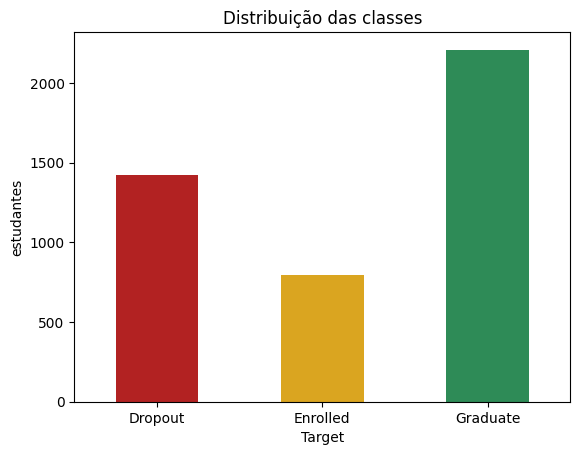

In [5]:
contagem = tabela["Target"].value_counts().reindex(cfg.CLASS_NAMES)

distribuicao = pd.DataFrame({
    "estudantes": contagem,
    "proporcao_%": (contagem / contagem.sum() * 100).round(1),
})
print(distribuicao)
print()
print("razão entre a maior e a menor classe:", round(contagem.max() / contagem.min(), 2))

contagem.plot(kind="bar", color=["firebrick", "goldenrod", "seagreen"])
plt.title("Distribuição das classes")
plt.xlabel("Target")
plt.ylabel("estudantes")
plt.xticks(rotation=0)
plt.show()

A distribuição é desbalanceada: há 2,78 vezes mais `Graduate` do que `Enrolled`. Um modelo que chutasse `Graduate` para todos acertaria metade dos casos, então a acurácia sozinha não serve para escolher nem para avaliar o modelo. Por isso a escolha usa F1 macro e revocação de `Dropout`, e a avaliação mostra também a acurácia balanceada.

O dicionário de dados abaixo vem de `config.FEATURES`, que é o mesmo contrato exposto pela API em `GET /api/features`: nome no CSV, nome usado na API, rótulo, tipo e o grupo temático usado no relatório.

In [6]:
GRUPOS = {
    "Perfil do estudante": ["marital_status", "nationality", "gender", "age_at_enrollment",
                            "international", "displaced", "educational_special_needs"],
    "Ingresso e formação anterior": ["application_mode", "application_order", "course",
                                     "daytime_evening_attendance", "previous_qualification",
                                     "previous_qualification_grade", "admission_grade"],
    "Contexto familiar": ["mothers_qualification", "fathers_qualification",
                          "mothers_occupation", "fathers_occupation"],
    "Situação financeira": ["debtor", "tuition_fees_up_to_date", "scholarship_holder"],
    "Desempenho no 1º semestre": [n for n in cfg.FEATURE_NAMES if n.startswith("curricular_units_1st")],
    "Desempenho no 2º semestre": [n for n in cfg.FEATURE_NAMES if n.startswith("curricular_units_2nd")],
    "Indicadores econômicos": ["unemployment_rate", "inflation_rate", "gdp"],
}
grupo_de = {atributo: grupo for grupo, atributos in GRUPOS.items() for atributo in atributos}
assert sorted(grupo_de) == sorted(cfg.FEATURE_NAMES), "todo atributo do contrato precisa de um grupo"

dicionario = pd.DataFrame(cfg.FEATURES)
dicionario["grupo"] = dicionario["api"].map(grupo_de)

print(dicionario["kind"].value_counts().to_string())
print()
print(dicionario.groupby("grupo", sort=False).size().to_string())
dicionario[["grupo", "api", "label", "kind", "csv"]]

kind
numeric        19
categorical     9
binary          8

grupo
Perfil do estudante             7
Ingresso e formação anterior    7
Contexto familiar               4
Situação financeira             3
Desempenho no 1º semestre       6
Desempenho no 2º semestre       6
Indicadores econômicos          3


,grupo,api,label,kind,csv
0,Perfil do estudante,marital_status,Estado civil,categorical,Marital status
1,Ingresso e formação anterior,application_mode,Modalidade de ingresso,categorical,Application mode
2,Ingresso e formação anterior,application_order,Ordem de opção do curso,numeric,Application order
3,Ingresso e formação anterior,course,Curso,categorical,Course
4,Ingresso e formação anterior,daytime_evening_attendance,"Turno (1=diurno, 0=noturno)",binary,Daytime/evening attendance
5,Ingresso e formação anterior,previous_qualification,Qualificação anterior,categorical,Previous qualification
6,Ingresso e formação anterior,previous_qualification_grade,Nota da qualificação anterior,numeric,Previous qualification (grade)
7,Perfil do estudante,nationality,Nacionalidade,categorical,Nacionality
8,Contexto familiar,mothers_qualification,Escolaridade da mãe,categorical,Mother's qualification
9,Contexto familiar,fathers_qualification,Escolaridade do pai,categorical,Father's qualification


In [7]:
nominais = dicionario.loc[dicionario["kind"] == "categorical", "csv"]
print("códigos distintos nas colunas nominais:")
print(tabela[nominais].nunique().to_string())

códigos distintos nas colunas nominais:
Marital status             6
Application mode          18
Course                    17
Previous qualification    17
Nacionality               21
Mother's qualification    29
Father's qualification    34
Mother's occupation       32
Father's occupation       46


As colunas `categorical` são códigos nominais do dataset original: o curso 171 não é "maior" que o curso 33. O pipeline não aplica one-hot nelas, e isso aparece de novo como limitação na etapa 8.

Para a exploração a seguir, as colunas são exibidas com os nomes da API, que são mais curtos.

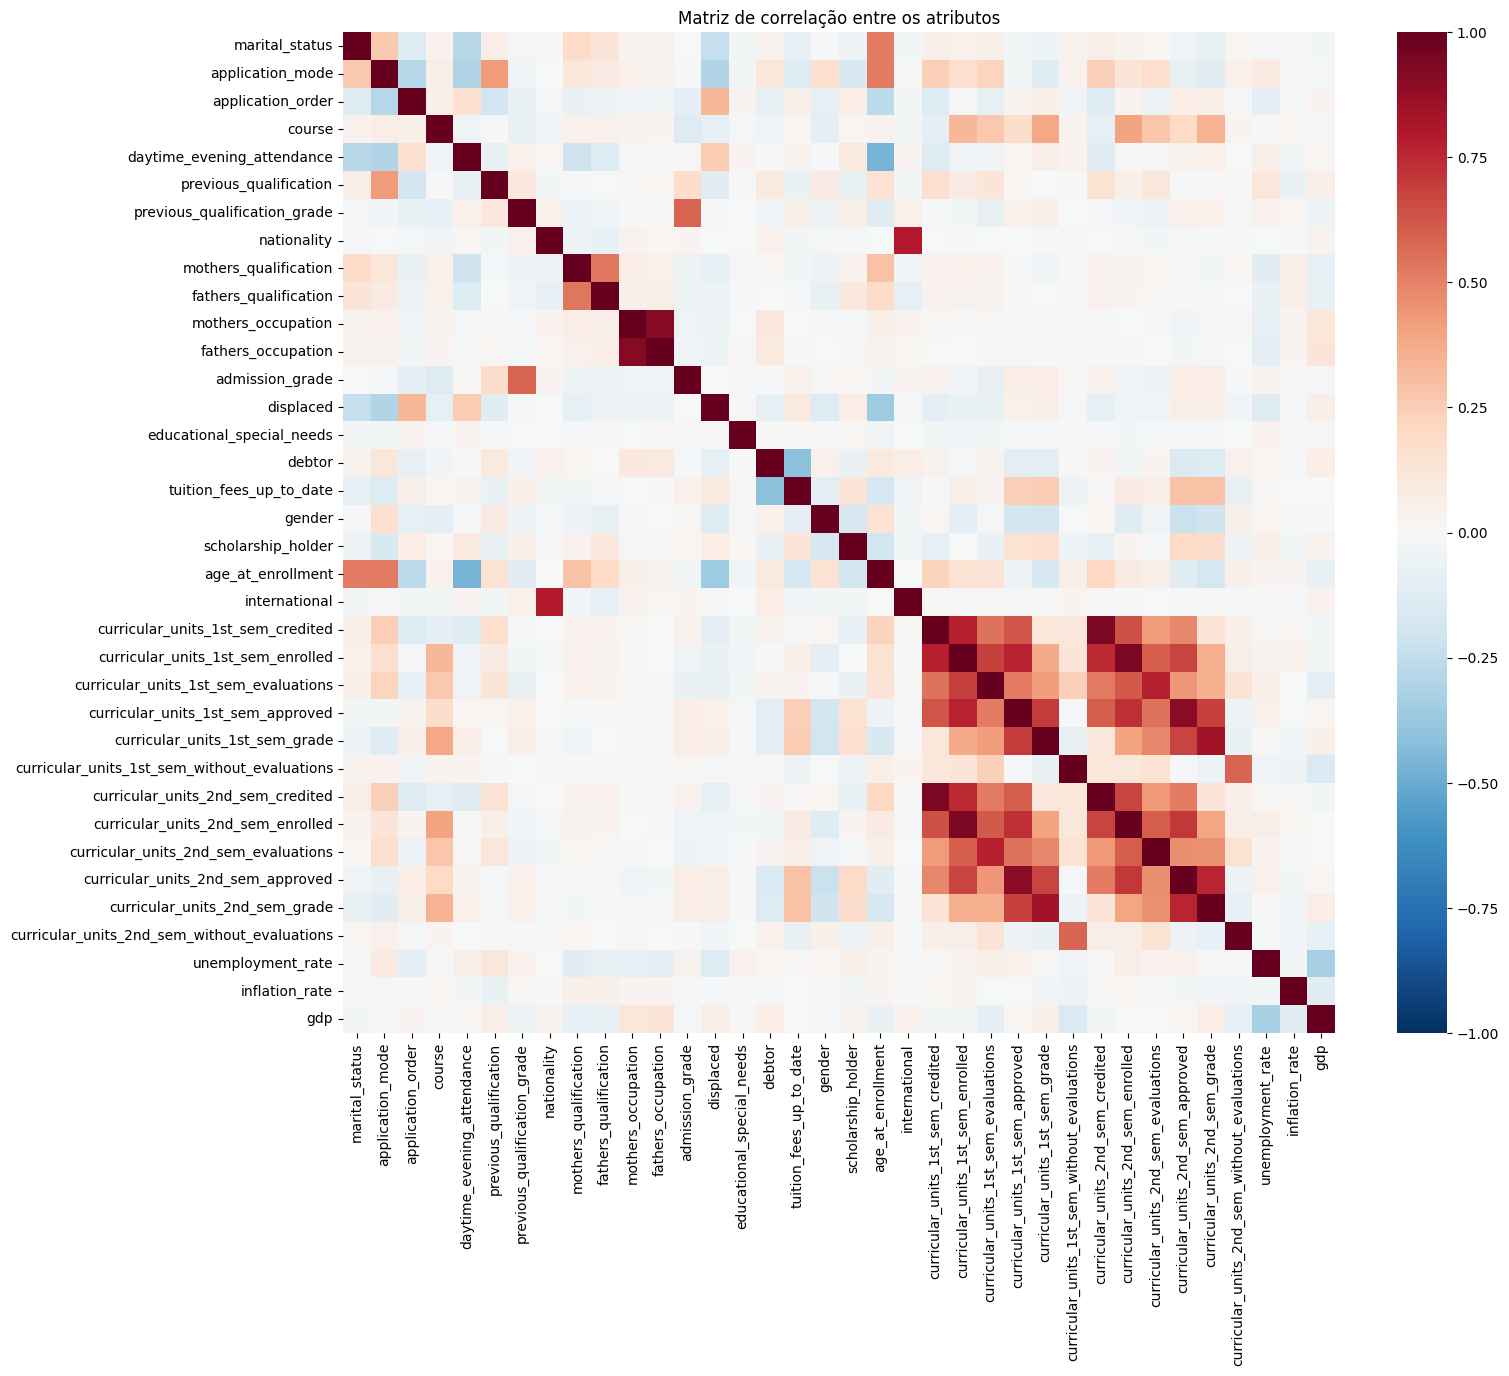

In [8]:
explorar = tabela.rename(columns=cfg.CSV_TO_API)

plt.figure(figsize=(16, 13))
sns.heatmap(explorar[cfg.FEATURE_NAMES].corr(), cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Matriz de correlação entre os atributos")
plt.show()

O alvo tem três classes sem ordem entre si, então correlacionar os atributos com um código 0/1/2 não teria significado. Para medir a relação de cada atributo com a evasão, a correlação é calculada contra um indicador binário "evadiu".

In [9]:
evadiu = (explorar["Target"] == "Dropout").astype(int)
correlacao = explorar[cfg.FEATURE_NAMES].corrwith(evadiu).sort_values()

print("correlação com o indicador de evasão (10 mais negativas e 5 mais positivas):")
print(pd.concat([correlacao.head(10), correlacao.tail(5)]).round(3).to_string())

correlação com o indicador de evasão (10 mais negativas e 5 mais positivas):
curricular_units_2nd_sem_grade         -0.572
curricular_units_2nd_sem_approved      -0.570
curricular_units_1st_sem_grade         -0.481
curricular_units_1st_sem_approved      -0.479
tuition_fees_up_to_date                -0.429
scholarship_holder                     -0.245
curricular_units_2nd_sem_evaluations   -0.155
curricular_units_2nd_sem_enrolled      -0.142
curricular_units_1st_sem_enrolled      -0.125
displaced                              -0.107
marital_status                          0.094
application_mode                        0.198
gender                                  0.204
debtor                                  0.229
age_at_enrollment                       0.254


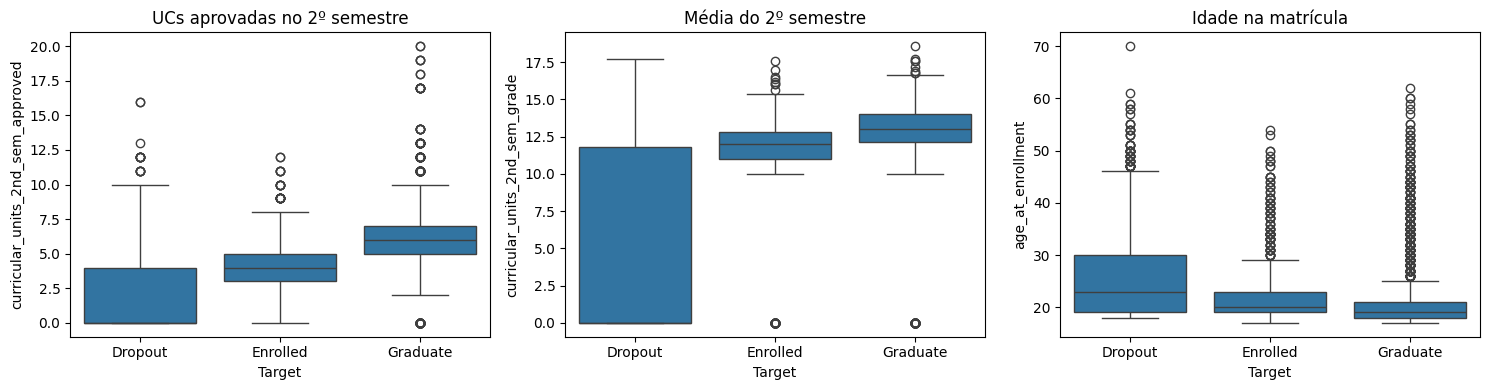

In [10]:
fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x="Target", y="curricular_units_2nd_sem_approved", data=explorar,
            order=cfg.CLASS_NAMES, ax=eixos[0])
eixos[0].set_title("UCs aprovadas no 2º semestre")
sns.boxplot(x="Target", y="curricular_units_2nd_sem_grade", data=explorar,
            order=cfg.CLASS_NAMES, ax=eixos[1])
eixos[1].set_title("Média do 2º semestre")
sns.boxplot(x="Target", y="age_at_enrollment", data=explorar,
            order=cfg.CLASS_NAMES, ax=eixos[2])
eixos[2].set_title("Idade na matrícula")
plt.tight_layout()
plt.show()

In [11]:
print("situação por mensalidades em dia (proporção por linha):")
print(pd.crosstab(explorar["tuition_fees_up_to_date"], explorar["Target"],
                  normalize="index")[cfg.CLASS_NAMES].round(3))
print()
print("situação por bolsa (proporção por linha):")
print(pd.crosstab(explorar["scholarship_holder"], explorar["Target"],
                  normalize="index")[cfg.CLASS_NAMES].round(3))

situação por mensalidades em dia (proporção por linha):
Target                   Dropout  Enrolled  Graduate
tuition_fees_up_to_date                             
0                          0.866     0.080     0.055
1                          0.247     0.193     0.560

situação por bolsa (proporção por linha):
Target              Dropout  Enrolled  Graduate
scholarship_holder                             
0                     0.387     0.200     0.413
1                     0.122     0.118     0.760


O desempenho acadêmico é o que mais separa as classes: quem evade aprova muito menos unidades curriculares e tem média menor, sobretudo no 2º semestre. Entre os fatores não acadêmicos, as mensalidades se destacam: 86,6% de quem não está com as mensalidades em dia evadiu, contra 24,7% de quem está. Bolsistas evadem bem menos (12,2% contra 38,7%).

## 3. Preparação

A preparação usa as funções de `prepare_data.py`, as mesmas que rodam em `npm run ml:prepare`:

- `validate_contract` confere se todas as colunas do contrato existem no CSV (e descarta colunas fora dele);
- `clean` mantém só as colunas do contrato e o alvo, remove duplicadas, remove linhas sem alvo, imputa ausentes pela mediana e recusa rótulos fora do mapeamento fixo.

A imputação está implementada para uma versão futura da base que precise dela; nesta base nenhuma correção é necessária.

In [12]:
prep.validate_contract(tabela)

relatorio = {}
limpa = prep.clean(tabela, relatorio)

print()
print("linhas removidas:", relatorio["rows_removed"])

  linhas após limpeza       : 4424 (removidas 0)
    - Mantidas as 36 colunas do contrato de features + alvo; colunas fora do contrato descartadas.
    - Nenhuma linha duplicada encontrada.
    - Nenhum valor ausente nos atributos — nenhuma imputação aplicada.

linhas removidas: 0


## 4. Transformação

`prepare_data.transform` passa as colunas para os nomes da API e codifica o alvo com o mapeamento fixo `Dropout = 0`, `Enrolled = 1`, `Graduate = 2`. É o mesmo mapeamento que `predict.py` usa para traduzir a predição de volta em texto.

In [13]:
dados = prep.transform(limpa)

print("mapeamento do alvo:", cfg.LABEL_MAP)
print("formato:", dados.shape)
dados.head()

mapeamento do alvo: {'Dropout': 0, 'Enrolled': 1, 'Graduate': 2}
formato: (4424, 37)


,marital_status,application_mode,application_order,course,daytime_evening_attendance,previous_qualification,previous_qualification_grade,nationality,mothers_qualification,fathers_qualification,...,curricular_units_2nd_sem_credited,curricular_units_2nd_sem_enrolled,curricular_units_2nd_sem_evaluations,curricular_units_2nd_sem_approved,curricular_units_2nd_sem_grade,curricular_units_2nd_sem_without_evaluations,unemployment_rate,inflation_rate,gdp,target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,0
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,2
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,0
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,2
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,2


Antes da padronização vem a divisão: 80% para desenvolvimento e 20% para teste, estratificada pelas três classes e com semente fixa (`RANDOM_STATE = 42`), pela mesma função de `train_model.py`. O conjunto de teste fica guardado e é usado **uma única vez**, na avaliação final (etapa 7). Os 80% se chamam "desenvolvimento" porque, dentro deles, a validação cruzada ainda separa treino e validação.

In [14]:
x = dados[cfg.FEATURE_NAMES]
y = dados[cfg.TARGET_COLUMN]

x_dev, x_teste, y_dev, y_teste = tm.split_development_test(x, y)

divisao = pd.DataFrame({
    "desenvolvimento": y_dev.value_counts(),
    "teste": y_teste.value_counts(),
}).rename(index=cfg.INVERSE_LABEL_MAP).reindex(cfg.CLASS_NAMES)
divisao["total"] = divisao.sum(axis=1)
divisao.loc["TOTAL"] = divisao.sum()
print(divisao)
print()
from sklearn.model_selection import StratifiedKFold

folds = StratifiedKFold(n_splits=cfg.CV_SPLITS, shuffle=True, random_state=cfg.RANDOM_STATE)
tamanhos = sorted({(len(treino), len(validacao)) for treino, validacao in folds.split(x_dev, y_dev)})
print(f"validação cruzada ({cfg.CV_SPLITS} folds), treino x validação por rodada:", tamanhos)

          desenvolvimento  teste  total
target                                 
Dropout              1137    284   1421
Enrolled              635    159    794
Graduate             1767    442   2209
TOTAL                3539    885   4424

validação cruzada (10 folds), treino x validação por rodada: [(3185, 354), (3186, 353)]


Os atributos são padronizados com `StandardScaler` (média 0 e desvio 1). O padronizador é ajustado **só no desenvolvimento**; o teste é apenas transformado com a média e o desvio do desenvolvimento, então nenhuma informação do teste entra no modelo. Na validação cruzada da etapa 6 o padronizador vai dentro de um `Pipeline` e é reajustado em cada fold.

In [15]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler().fit(x_dev)
x_dev_padronizado = scaler.transform(x_dev)
x_teste_padronizado = scaler.transform(x_teste)

print("desenvolvimento: média", round(float(x_dev_padronizado.mean()), 4),
      "| desvio", round(float(x_dev_padronizado.std()), 4))
print("teste:           média", round(float(x_teste_padronizado.mean()), 4),
      "| desvio", round(float(x_teste_padronizado.std()), 4))

desenvolvimento: média 0.0 | desvio 1.0
teste:           média 0.0059 | desvio 1.0127


## 5. Seleção de atributos

O conjunto de atributos do modelo é o contrato de 36 colunas definido em `config.FEATURES`. É a mesma lista que a API publica em `GET /api/features` e que a Web e o Mobile usam para montar os formulários. Nenhuma coluna da base foi descartada: não existe identificador de aluno nem coluna sem valor preditivo.

Para ver quanto cada atributo separa as três classes isoladamente, o escore ANOVA F (`f_classif`) é calculado sobre o desenvolvimento.

In [16]:
from sklearn.feature_selection import SelectKBest, f_classif

seletor = SelectKBest(score_func=f_classif, k="all")
seletor.fit(x_dev, y_dev)

escores = pd.DataFrame({"atributo": cfg.FEATURE_NAMES, "escore_f": seletor.scores_})
escores["grupo"] = escores["atributo"].map(grupo_de)
escores = escores.sort_values("escore_f", ascending=False)
print(escores.round(2).to_string(index=False))

                                    atributo  escore_f                        grupo
           curricular_units_2nd_sem_approved   1092.91    Desempenho no 2º semestre
              curricular_units_2nd_sem_grade    911.94    Desempenho no 2º semestre
           curricular_units_1st_sem_approved    660.29    Desempenho no 1º semestre
              curricular_units_1st_sem_grade    573.05    Desempenho no 1º semestre
                     tuition_fees_up_to_date    406.06          Situação financeira
                          scholarship_holder    176.60          Situação financeira
                           age_at_enrollment    124.84          Perfil do estudante
                                      debtor    120.67          Situação financeira
                            application_mode    105.42 Ingresso e formação anterior
                                      gender     97.05          Perfil do estudante
        curricular_units_2nd_sem_evaluations     68.78    Desempenho no 2º s

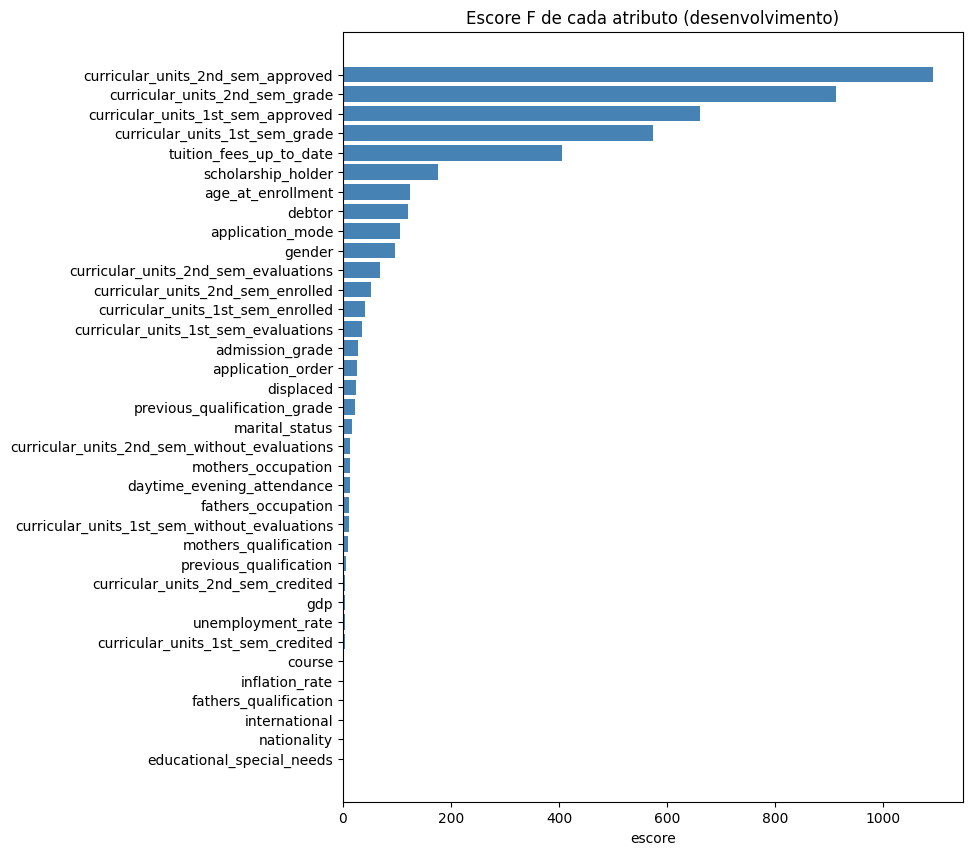

In [17]:
plt.figure(figsize=(8, 10))
plt.barh(escores["atributo"], escores["escore_f"], color="steelblue")
plt.gca().invert_yaxis()
plt.title("Escore F de cada atributo (desenvolvimento)")
plt.xlabel("escore")
plt.show()

Os escores confirmam a exploração: unidades aprovadas e médias do 1º e do 2º semestre e mensalidades em dia lideram, e os indicadores econômicos, a nacionalidade e as necessidades educacionais especiais quase não separam as classes sozinhos.

Mesmo assim os 36 atributos são mantidos: um atributo fraco isolado ainda pode ajudar em combinação com os outros, e a regressão logística, com regularização, dá pouco peso ao que não contribui. Essa decisão é verificada na etapa 8, testando se um subconjunto menor manteria o desempenho.

## 6. Treinamento

Em vez de partir de um algoritmo só, 13 candidatos de classificação multiclasse são comparados, incluindo variantes com `class_weight="balanced"`. Cada um roda dentro de um `Pipeline(StandardScaler → modelo)`.

A regra de escolha foi fixada antes de olhar os resultados e é medida por validação cruzada estratificada de 10 folds sobre o desenvolvimento:

1. **Filtro de estabilidade:** sai da disputa quem tem distância entre acurácia de treino e de validação acima de 0,05 (5 p.p.).
2. **Score de seleção:** `0,50 × F1 macro + 0,50 × revocação de Dropout`.
3. **Desempate por parcimônia:** candidatos a até 0,01 do melhor score são equivalentes, e entre eles vence o de menor distância treino-validação.

In [18]:
for nome, estimador in tm.build_candidates().items():
    print(f"{nome:<40} {estimador}")

LogisticRegression                       LogisticRegression(max_iter=1000, random_state=42)
LogisticRegressionBalanced               LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)
LinearDiscriminantAnalysis               LinearDiscriminantAnalysis()
LinearDiscriminantAnalysisDropoutPrior   LinearDiscriminantAnalysis(priors=[0.45, 0.25, 0.3])
KNeighborsClassifier                     KNeighborsClassifier(n_neighbors=15)
DecisionTreeClassifier                   DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42)
DecisionTreeBalanced                     DecisionTreeClassifier(class_weight='balanced', max_depth=8,
                       min_samples_leaf=10, random_state=42)
GaussianNB                               GaussianNB()
SVC                                      SVC(probability=True, random_state=42)
SVCBalanced                              SVC(class_weight='balanced', probability=True, random_state=42)
RandomForestClassifier          

In [19]:
avaliados = tm.select_by_cross_validation(x_dev, y_dev)


[passo 4] seleção por validação cruzada (10 folds estratificados) sobre o conjunto de desenvolvimento
          o conjunto de teste não participa desta etapa
  algoritmo                                  F1 macro   rec.Dropout     score       gap


  LogisticRegression                           0.6774        0.7635    0.7205    0.0087


  LogisticRegressionBalanced                   0.7069        0.7178    0.7124    0.0120


  LinearDiscriminantAnalysis                   0.6817        0.6905    0.6861    0.0068


  LinearDiscriminantAnalysisDropoutPrior       0.6910        0.7117    0.7013    0.0108


...

  SVC                                          0.6711        0.7284    0.6998    0.0692


  SVCBalanced                                  0.6981        0.6906    0.6944    0.0807


  RandomForestClassifier                       0.6869        0.7618    0.7244    0.1956


  RandomForestBalanced                         0.7105        0.7583    0.7344    0.2065


  GradientBoostingClassifier                   0.6979        0.7653    0.7316    0.0727


In [20]:
candidatos = pd.DataFrame(avaliados).set_index("algorithm")
candidatos["situacao"] = np.where(candidatos["overfit_gap"] <= tm.MAX_OVERFIT_GAP, "elegível", "descartado")
candidatos = candidatos.sort_values("cv_selection_score", ascending=False)

colunas = ["cv_selection_score", "cv_f1_macro_mean", "cv_recall_dropout_mean",
           "cv_accuracy_mean", "cv_train_accuracy_mean", "overfit_gap", "situacao"]
candidatos[colunas]

,cv_selection_score,cv_f1_macro_mean,cv_recall_dropout_mean,cv_accuracy_mean,cv_train_accuracy_mean,overfit_gap,situacao
algorithm,,,,,,,
RandomForestBalanced,0.7344,0.7105,0.7583,0.7776,0.9841,0.2065,descartado
GradientBoostingClassifier,0.7316,0.6979,0.7653,0.7742,0.8469,0.0727,descartado
RandomForestClassifier,0.7244,0.6869,0.7618,0.7737,0.9693,0.1956,descartado
LogisticRegression,0.7205,0.6774,0.7635,0.7652,0.7739,0.0087,elegível
LogisticRegressionBalanced,0.7124,0.7069,0.7178,0.7471,0.7591,0.0120,elegível
LinearDiscriminantAnalysisDropoutPrior,0.7013,0.6910,0.7117,0.7420,0.7528,0.0108,elegível
SVC,0.6998,0.6711,0.7284,0.7587,0.8279,0.0692,descartado
SVCBalanced,0.6944,0.6981,0.6906,0.7395,0.8202,0.0807,descartado
LinearDiscriminantAnalysis,0.6861,0.6817,0.6905,0.7570,0.7638,0.0068,elegível


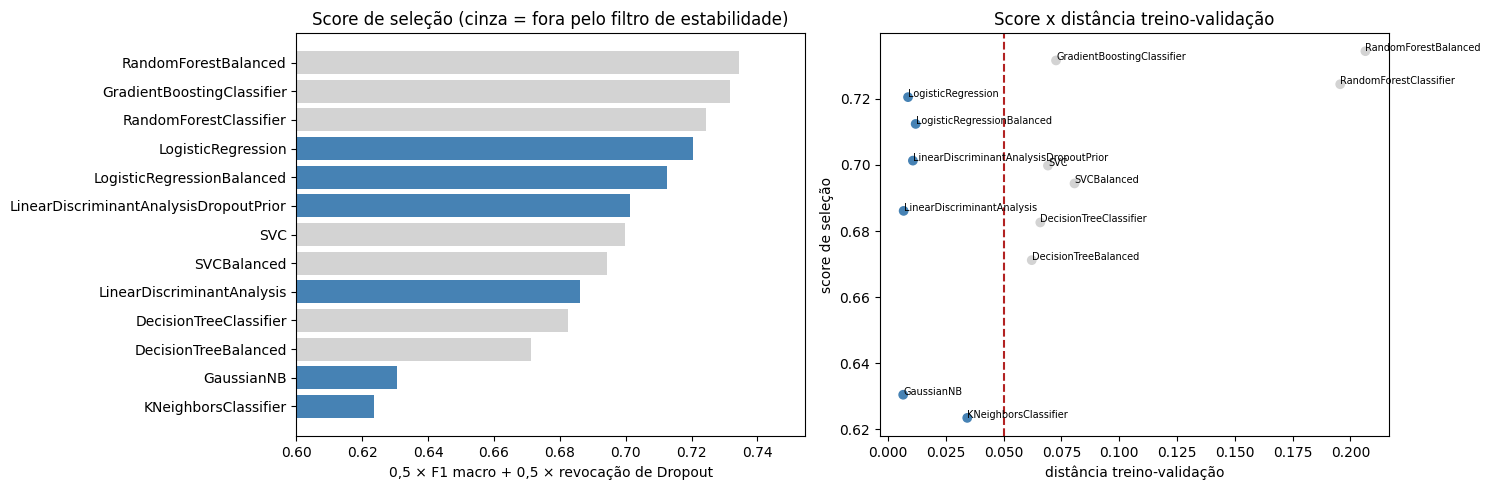

In [21]:
cores = np.where(candidatos["situacao"] == "elegível", "steelblue", "lightgray")

fig, eixos = plt.subplots(1, 2, figsize=(15, 5))

eixos[0].barh(candidatos.index, candidatos["cv_selection_score"], color=cores)
eixos[0].invert_yaxis()
eixos[0].set_xlim(0.6, candidatos["cv_selection_score"].max() + 0.02)
eixos[0].set_title("Score de seleção (cinza = fora pelo filtro de estabilidade)")
eixos[0].set_xlabel("0,5 × F1 macro + 0,5 × revocação de Dropout")

eixos[1].scatter(candidatos["overfit_gap"], candidatos["cv_selection_score"], c=cores)
for nome, linha in candidatos.iterrows():
    eixos[1].annotate(nome, (linha["overfit_gap"], linha["cv_selection_score"]), fontsize=7)
eixos[1].axvline(tm.MAX_OVERFIT_GAP, color="firebrick", linestyle="--")
eixos[1].set_title("Score x distância treino-validação")
eixos[1].set_xlabel("distância treino-validação")
eixos[1].set_ylabel("score de seleção")

plt.tight_layout()
plt.show()

In [22]:
import textwrap

vencedor = tm.select_final(avaliados)
criterio = vencedor["selection_criteria"]

print("modelo escolhido:", vencedor["algorithm"])
print("fora pelo filtro de estabilidade:", criterio["excluded_by_stability_filter"])
print("equivalentes (até 0,01 do melhor score):", criterio["equivalent_candidates"])
print("custo frente ao melhor excluído:", criterio["cost_vs_best_excluded"])
print()
print(textwrap.fill(vencedor["selection_rationale"], width=110))

modelo escolhido: LogisticRegression
fora pelo filtro de estabilidade: ['DecisionTreeClassifier', 'DecisionTreeBalanced', 'SVC', 'SVCBalanced', 'RandomForestClassifier', 'RandomForestBalanced', 'GradientBoostingClassifier']
equivalentes (até 0,01 do melhor score): ['LogisticRegression', 'LogisticRegressionBalanced']
custo frente ao melhor excluído: {'algorithm': 'RandomForestBalanced', 'f1_macro_delta': -0.0331, 'recall_dropout_delta': 0.0052}

Critério fixado antes de olhar os resultados e medido por validação cruzada de 10 folds sobre o conjunto de
desenvolvimento — o conjunto de teste não participa de nenhuma etapa da escolha, para que as métricas
publicadas não sejam otimistas. (1) Filtro de estabilidade: seguem na disputa apenas os candidatos cuja
distância entre acurácia de treino e de validação fica em até 0.05, o que privilegia modelos cujo desempenho
medido se sustenta fora do treino. O filtro exclui os ensembles por construção — uma floresta com folhas
pequenas ajusta quase i

Os três maiores scores (as duas florestas aleatórias e o gradient boosting) ficaram fora pelo filtro de estabilidade: a floresta balanceada acerta 98,4% no treino e 77,8% na validação. O filtro é uma preferência deliberada por modelos estáveis, e o custo dele é publicado: frente à melhor floresta, a regressão logística abre mão de 0,0331 de F1 macro, mas encontra mais evasores (+0,0052 de revocação de Dropout). As duas regressões logísticas ficaram a menos de 0,01 uma da outra, e venceu a de menor distância treino-validação (0,0087).

O modelo final é ajustado em todo o desenvolvimento, sobre os dados padronizados na etapa 4.

In [23]:
algoritmo = vencedor["algorithm"]
modelo = tm.build_candidates()[algoritmo]
modelo.fit(x_dev_padronizado, y_dev)

print(modelo)
print("acurácia no desenvolvimento:", round(modelo.score(x_dev_padronizado, y_dev), 4))

LogisticRegression(max_iter=1000, random_state=42)
acurácia no desenvolvimento: 0.7731


## 7. Avaliação

As métricas abaixo são calculadas uma única vez, sobre os 885 estudantes do teste, que não participaram de nenhum ajuste nem da escolha do algoritmo.

In [24]:
from sklearn import metrics

previsao = modelo.predict(x_teste_padronizado)
probabilidades = modelo.predict_proba(x_teste_padronizado)

def revocacao(y_real, y_previsto, classe):
    return metrics.recall_score(y_real, y_previsto, labels=[cfg.LABEL_MAP[classe]], average="macro")

linha_vencedor = candidatos.loc[algoritmo]
resultado = pd.DataFrame({
    "validacao_cruzada": [linha_vencedor["cv_accuracy_mean"], None,
                          linha_vencedor["cv_f1_macro_mean"], linha_vencedor["cv_recall_dropout_mean"]],
    "teste": [metrics.accuracy_score(y_teste, previsao),
              metrics.balanced_accuracy_score(y_teste, previsao),
              metrics.f1_score(y_teste, previsao, average="macro"),
              revocacao(y_teste, previsao, "Dropout")],
}, index=["acurácia", "acurácia balanceada", "F1 macro", "revocação de Dropout"])
print(resultado.round(4))
print()
print("distância desenvolvimento-teste (acurácia):",
      round(modelo.score(x_dev_padronizado, y_dev) - metrics.accuracy_score(y_teste, previsao), 4))

                      validacao_cruzada   teste
acurácia                         0.7652  0.7684
acurácia balanceada                 NaN  0.6754
F1 macro                         0.6774  0.6826
revocação de Dropout             0.7635  0.7676

distância desenvolvimento-teste (acurácia): 0.0047


Como a evasão é o foco do projeto, o desempenho nessa classe é detalhado separadamente, tratando o problema como "evade x não evade".

In [25]:
dropout = cfg.LABEL_MAP["Dropout"]
real = y_teste.to_numpy() == dropout
previsto = previsao == dropout

vp = int((real & previsto).sum())
fn = int((real & ~previsto).sum())
fp = int((~real & previsto).sum())
vn = int((~real & ~previsto).sum())

print(f"revocação:      {vp / (vp + fn):.4f}  ({vp} dos {vp + fn} evasores reais identificados)")
print(f"precisão:       {vp / (vp + fp):.4f}  ({vp} dos {vp + fp} apontados como evasão evadiram)")
print(f"F1:             {metrics.f1_score(real, previsto):.4f}")
print(f"especificidade: {vn / (vn + fp):.4f}  ({vn} dos {vn + fp} não evasores classificados corretamente)")
print(f"acurácia evade x não evade: {(vp + vn) / len(real):.4f}  ({vp + vn} acertos em {len(real)})")

revocação:      0.7676  (218 dos 284 evasores reais identificados)
precisão:       0.7927  (218 dos 275 apontados como evasão evadiram)
F1:             0.7800
especificidade: 0.9052  (544 dos 601 não evasores classificados corretamente)
acurácia evade x não evade: 0.8610  (762 acertos em 885)


          Dropout  Enrolled  Graduate
Dropout       218        29        37
Enrolled       43        53        63
Graduate       14        19       409



              precision    recall  f1-score   support

     Dropout     0.7927    0.7676    0.7800       284
    Enrolled     0.5248    0.3333    0.4077       159
    Graduate     0.8035    0.9253    0.8601       442

    accuracy                         0.7684       885
   macro avg     0.7070    0.6754    0.6826       885
weighted avg     0.7500    0.7684    0.7531       885



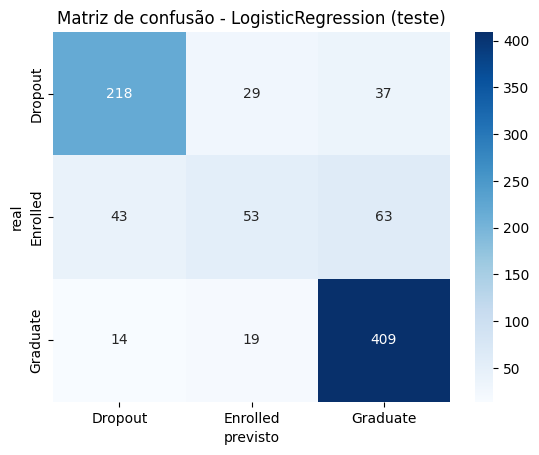

In [26]:
matriz = metrics.confusion_matrix(y_teste, previsao)
print(pd.DataFrame(matriz, index=cfg.CLASS_NAMES, columns=cfg.CLASS_NAMES))
print()
print(metrics.classification_report(y_teste, previsao, target_names=cfg.CLASS_NAMES, digits=4))

sns.heatmap(matriz, annot=True, fmt="d", cmap="Blues",
            xticklabels=cfg.CLASS_NAMES, yticklabels=cfg.CLASS_NAMES)
plt.title(f"Matriz de confusão - {algoritmo} (teste)")
plt.xlabel("previsto")
plt.ylabel("real")
plt.show()

O campo `confidence` que a API devolve é a maior probabilidade do `predict_proba`. Para saber se esse número pode ser lido como probabilidade, a calibração é medida no teste: em cada faixa de confiança, compara-se a confiança média anunciada com a taxa de acerto real. O ECE é a média ponderada dessas diferenças; abaixo de 0,05 é considerado bem calibrado.

ECE: 0.0159 | MCE: 0.0638 | log loss: 0.5846

            confianca_media  taxa_acerto  casos
(0.3, 0.4]            0.379        0.318     22
(0.4, 0.5]            0.455        0.467     92
(0.5, 0.6]            0.547        0.611    113
(0.6, 0.7]            0.648        0.659     82
(0.7, 0.8]            0.754        0.761    113
(0.8, 0.9]            0.855        0.844    180
(0.9, 1.0]            0.953        0.951    283


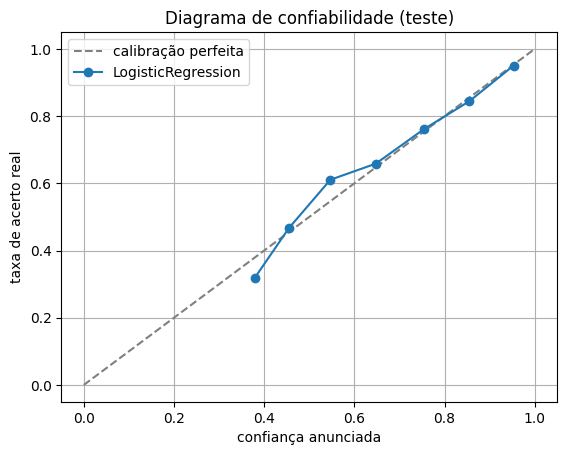

In [27]:
ece, mce = tm.calibration_error(y_teste, previsao, probabilidades)
print("ECE:", ece, "| MCE:", mce, "| log loss:", round(metrics.log_loss(y_teste, probabilidades), 4))
print()

confianca = probabilidades.max(axis=1)
acerto = previsao == y_teste.to_numpy()
faixas = pd.cut(confianca, bins=np.linspace(0, 1, 11), include_lowest=True)
calibracao = (pd.DataFrame({"confianca": confianca, "acerto": acerto})
              .groupby(faixas, observed=True)
              .agg(confianca_media=("confianca", "mean"),
                   taxa_acerto=("acerto", "mean"),
                   casos=("acerto", "size")))
print(calibracao.round(3))

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="calibração perfeita")
plt.plot(calibracao["confianca_media"], calibracao["taxa_acerto"], marker="o", label=algoritmo)
plt.title("Diagrama de confiabilidade (teste)")
plt.xlabel("confiança anunciada")
plt.ylabel("taxa de acerto real")
plt.legend()
plt.grid(True)
plt.show()

In [28]:
por_classe = pd.DataFrame({
    "probabilidade_media": probabilidades.mean(axis=0),
    "frequencia_real": [(y_teste == i).mean() for i in modelo.classes_],
}, index=[cfg.INVERSE_LABEL_MAP[i] for i in modelo.classes_])
print(por_classe.round(4))
print()

p_dropout = probabilidades[:, list(modelo.classes_).index(dropout)]
faixas_dropout = pd.cut(p_dropout, bins=[0, 0.2, 0.4, 0.6, 0.8, 1.0], include_lowest=True)
risco = (pd.DataFrame({"p_dropout": p_dropout, "evadiu": real})
         .groupby(faixas_dropout, observed=True)
         .agg(probabilidade_media=("p_dropout", "mean"),
              taxa_real_de_evasao=("evadiu", "mean"),
              casos=("evadiu", "size")))
risco["superestimativa"] = risco["probabilidade_media"] - risco["taxa_real_de_evasao"]
print("calibração da probabilidade de evasão, por faixa:")
print(risco.round(3))

          probabilidade_media  frequencia_real
Dropout                0.3225           0.3209
Enrolled               0.1878           0.1797
Graduate               0.4897           0.4994

calibração da probabilidade de evasão, por faixa:
               probabilidade_media  taxa_real_de_evasao  casos  \
(-0.001, 0.2]                0.058                0.073    492   
(0.2, 0.4]                   0.290                0.189    106   
(0.4, 0.6]                   0.494                0.542     72   
(0.6, 0.8]                   0.704                0.694     49   
(0.8, 1.0]                   0.939                0.934    166   

               superestimativa  
(-0.001, 0.2]           -0.015  
(0.2, 0.4]               0.102  
(0.4, 0.6]              -0.048  
(0.6, 0.8]               0.010  
(0.8, 1.0]               0.006  


O modelo acerta 76,8% dos casos no teste, muito perto da validação cruzada (76,5%), e a acurácia cai só 0,47 p.p. do desenvolvimento para o teste: ele não decorou o treino.

Na evasão, ele encontra 218 dos 284 evasores (76,8%), e 79,3% dos estudantes apontados como evasão evadiram de fato. Dos 66 evasores não sinalizados, 37 foram classificados como formados. A acurácia geral de 76,8% vale para as três classes juntas; tratando o problema como "evade x não evade", ela é de 86,1%.

A classe `Enrolled` é a mais fraca: o modelo reconhece 53 dos 159 matriculados (33,3%) e manda 63 deles para `Graduate`. É ela que separa a acurácia (76,8%) da acurácia balanceada (67,5%). `Enrolled` é a menor classe e a mais ambígua, já que quem está matriculado ainda pode evadir ou se formar.

A confiança é bem calibrada: ECE de 0,0159, bem abaixo da referência de 0,05, e a probabilidade média de cada classe bate com a frequência real dentro de ±0,01. A exceção é a faixa em que a probabilidade de evasão fica entre 0,2 e 0,4: nos 106 casos dessa faixa o modelo anuncia, em média, 29,0% de risco, mas só 18,9% evadiram, uma superestimativa de cerca de 10 pontos.

## 8. Interpretação

### 8.1. Atributos mais influentes

A influência de cada atributo é a média do valor absoluto dos coeficientes da regressão logística nas três classes, sobre os atributos padronizados e normalizada para somar 1. É o mesmo cálculo gravado em `model_metadata.json` (`feature_importance`).

In [29]:
importancia, metodo = tm.compute_feature_importance(modelo)
importancia = pd.DataFrame(importancia)
importancia["grupo"] = importancia["feature"].map(grupo_de)
importancia["influencia_%"] = (importancia["importance"] * 100).round(1)

print("método:", metodo)
print(importancia.head(10)[["feature", "grupo", "influencia_%"]].to_string(index=False))
print()
print("os três primeiros somam:", round(importancia["importance"].head(3).sum() * 100, 1), "%")
print()
print(importancia.groupby("grupo")["importance"].sum().sort_values(ascending=False)
      .mul(100).round(1).to_string())

método: mean_abs_coefficient (média do |coeficiente| entre as classes, sobre features padronizadas, normalizada para somar 1)
                          feature                        grupo  influencia_%
curricular_units_2nd_sem_approved    Desempenho no 2º semestre          20.1
curricular_units_1st_sem_approved    Desempenho no 1º semestre          12.7
curricular_units_2nd_sem_enrolled    Desempenho no 2º semestre          11.9
          tuition_fees_up_to_date          Situação financeira           6.0
   curricular_units_2nd_sem_grade    Desempenho no 2º semestre           4.7
curricular_units_1st_sem_enrolled    Desempenho no 1º semestre           3.8
curricular_units_2nd_sem_credited    Desempenho no 2º semestre           3.5
                           course Ingresso e formação anterior           3.1
               mothers_occupation            Contexto familiar           2.9
                age_at_enrollment          Perfil do estudante           2.6

os três primeiros somam: 4

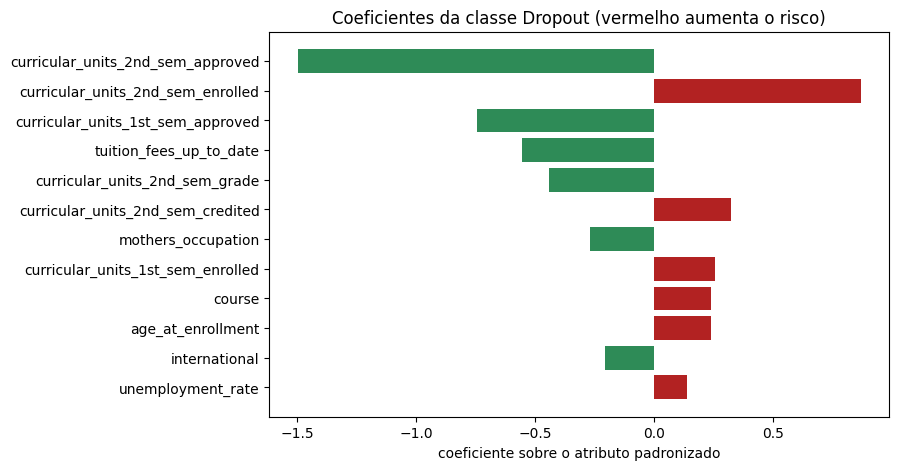

In [30]:
linha_dropout = list(modelo.classes_).index(dropout)
coeficientes = pd.Series(modelo.coef_[linha_dropout], index=cfg.FEATURE_NAMES)
principais = coeficientes.reindex(coeficientes.abs().sort_values(ascending=False).index).head(12)

plt.figure(figsize=(8, 5))
plt.barh(principais.index, principais.values,
         color=np.where(principais.values > 0, "firebrick", "seagreen"))
plt.gca().invert_yaxis()
plt.title("Coeficientes da classe Dropout (vermelho aumenta o risco)")
plt.xlabel("coeficiente sobre o atributo padronizado")
plt.show()

O desempenho acadêmico domina a decisão, e o fator não acadêmico mais relevante é a situação das mensalidades. Nas colunas nominais (curso, modalidade de ingresso, ocupação dos pais) o coeficiente não é interpretável, pela codificação descrita na etapa 2.

### 8.2. Verificação da seleção de atributos

A etapa 5 manteve os 36 atributos. Aqui isso é testado: o `SelectKBest` entra **dentro** do `Pipeline`, junto com o padronizador e o algoritmo escolhido, e a validação cruzada mede o desempenho para cada quantidade `k` de atributos. Assim o seletor é reajustado em cada fold e não vê os dados de validação.

In [31]:
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

pontuacao = {"accuracy": "accuracy", "f1_macro": "f1_macro",
             "recall_dropout": tm.DROPOUT_RECALL_SCORER}

resultados_k = []
for k in range(1, len(cfg.FEATURE_NAMES) + 1):
    pipeline = Pipeline([
        ("scaler", StandardScaler()),
        ("selecao", SelectKBest(score_func=f_classif, k=k)),
        ("modelo", tm.build_candidates()[algoritmo]),
    ])
    r = cross_validate(pipeline, x_dev, y_dev, cv=folds, scoring=pontuacao)
    f1 = r["test_f1_macro"].mean()
    rec = r["test_recall_dropout"].mean()
    resultados_k.append([k, r["test_accuracy"].mean(), f1, rec,
                         tm.selection_score(f1, rec), r["test_f1_macro"].std()])

resultados_k = pd.DataFrame(resultados_k, columns=["k", "acuracia", "f1_macro",
                                                   "revocacao_dropout", "score", "f1_desvio"])
print(resultados_k.round(4).to_string(index=False))

 k  acuracia  f1_macro  revocacao_dropout  score  f1_desvio
 1    0.7107    0.5130             0.7424 0.6277     0.0141
 2    0.7098    0.5199             0.7327 0.6263     0.0205
 3    0.7056    0.5243             0.7125 0.6184     0.0227
 4    0.7064    0.5266             0.7143 0.6204     0.0244
 5    0.7135    0.5521             0.7222 0.6371     0.0192
 6    0.7282    0.5872             0.7328 0.6600     0.0200
 7    0.7293    0.5962             0.7407 0.6684     0.0224
 8    0.7290    0.6001             0.7433 0.6717     0.0152
 9    0.7313    0.6058             0.7477 0.6768     0.0133
10    0.7301    0.6054             0.7424 0.6739     0.0174
11    0.7392    0.6470             0.7460 0.6965     0.0329
12    0.7601    0.6741             0.7398 0.7069     0.0251
13    0.7612    0.6773             0.7398 0.7086     0.0210
14    0.7595    0.6748             0.7363 0.7055     0.0262
15    0.7610    0.6759             0.7363 0.7061     0.0278
16    0.7615    0.6761             0.736

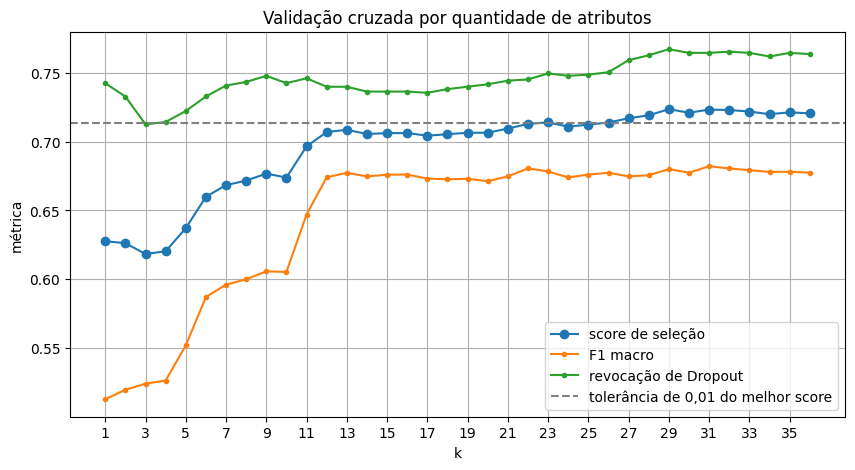

In [32]:
plt.figure(figsize=(10, 5))
plt.plot(resultados_k["k"], resultados_k["score"], marker="o", label="score de seleção")
plt.plot(resultados_k["k"], resultados_k["f1_macro"], marker=".", label="F1 macro")
plt.plot(resultados_k["k"], resultados_k["revocacao_dropout"], marker=".", label="revocação de Dropout")
plt.axhline(resultados_k["score"].max() - tm.EQUIVALENCE_TOLERANCE, color="gray",
            linestyle="--", label="tolerância de 0,01 do melhor score")
plt.title("Validação cruzada por quantidade de atributos")
plt.xlabel("k")
plt.ylabel("métrica")
plt.xticks(range(1, len(cfg.FEATURE_NAMES) + 1, 2))
plt.legend()
plt.grid(True)
plt.show()

Para escolher `k` vale a mesma regra de parcimônia da etapa 6: entre as quantidades a até 0,01 do melhor score, fica a menor. O modelo resultante é então comparado com o de 36 atributos no teste.

In [33]:
melhor_score = resultados_k["score"].max()
k_escolhido = int(resultados_k.loc[resultados_k["score"] >= melhor_score - tm.EQUIVALENCE_TOLERANCE, "k"].min())

seletor_final = SelectKBest(score_func=f_classif, k=k_escolhido).fit(x_dev, y_dev)
atributos_selecionados = list(x.columns[seletor_final.get_support()])

print("melhor score:", round(melhor_score, 4),
      "com k =", int(resultados_k.loc[resultados_k["score"].idxmax(), "k"]))
print("k escolhido:", k_escolhido)
print("atributos que ficariam de fora:", [a for a in cfg.FEATURE_NAMES if a not in atributos_selecionados])

scaler_sel = StandardScaler().fit(x_dev[atributos_selecionados])
modelo_selecao = tm.build_candidates()[algoritmo]
modelo_selecao.fit(scaler_sel.transform(x_dev[atributos_selecionados]), y_dev)
previsao_selecao = modelo_selecao.predict(scaler_sel.transform(x_teste[atributos_selecionados]))
probabilidades_selecao = modelo_selecao.predict_proba(scaler_sel.transform(x_teste[atributos_selecionados]))

def resumo(y_previsto, proba):
    return [metrics.accuracy_score(y_teste, y_previsto),
            metrics.balanced_accuracy_score(y_teste, y_previsto),
            metrics.f1_score(y_teste, y_previsto, average="macro"),
            revocacao(y_teste, y_previsto, "Dropout"),
            revocacao(y_teste, y_previsto, "Enrolled"),
            tm.calibration_error(y_teste, y_previsto, proba)[0]]

comparacao = pd.DataFrame(
    [resumo(previsao, probabilidades), resumo(previsao_selecao, probabilidades_selecao)],
    index=[f"{len(cfg.FEATURE_NAMES)} atributos (produção)", f"{k_escolhido} atributos"],
    columns=["acuracia", "acuracia_balanceada", "f1_macro", "rev_dropout", "rev_enrolled", "ece"],
)
print()
print("teste:")
print(comparacao.round(4).to_string())
print()
print("validação cruzada (score):",
      round(resultados_k.loc[resultados_k["k"] == len(cfg.FEATURE_NAMES), "score"].iloc[0], 4), "contra",
      round(resultados_k.loc[resultados_k["k"] == k_escolhido, "score"].iloc[0], 4))
print()
print(pd.DataFrame(metrics.confusion_matrix(y_teste, previsao_selecao),
                   index=cfg.CLASS_NAMES, columns=cfg.CLASS_NAMES))

melhor score: 0.7235 com k = 29
k escolhido: 23
atributos que ficariam de fora: ['course', 'previous_qualification', 'nationality', 'mothers_qualification', 'fathers_qualification', 'educational_special_needs', 'international', 'curricular_units_1st_sem_credited', 'curricular_units_1st_sem_without_evaluations', 'curricular_units_2nd_sem_credited', 'unemployment_rate', 'inflation_rate', 'gdp']

teste:
                         acuracia  acuracia_balanceada  f1_macro  rev_dropout  rev_enrolled     ece
36 atributos (produção)    0.7684               0.6754    0.6826       0.7676        0.3333  0.0159
23 atributos               0.7695               0.6763    0.6848       0.7570        0.3396  0.0391

validação cruzada (score): 0.7205 contra 0.7139

          Dropout  Enrolled  Graduate
Dropout       215        30        39
Enrolled       40        54        65
Graduate       13        17       412


O melhor score da validação cruzada foi com 29 atributos (0,7235), e a menor quantidade equivalente foi 23. Com 12 ou 13 atributos o F1 macro já chega ao nível do modelo completo, mas a revocação de Dropout fica em torno de 0,74 e só volta a 0,76 entre k = 27 e k = 29, quando entram, pela ordem do escore F, as UCs aproveitadas no 2º semestre, o PIB e a taxa de desemprego.

No teste, o modelo com 23 atributos ficou praticamente igual em acurácia (0,7695 contra 0,7684) e F1 macro (0,6848 contra 0,6826), mas encontrou 3 evasores a menos (revocação de Dropout de 0,757 contra 0,768) e a calibração piorou (ECE de 0,039 contra 0,016). Na validação cruzada o score também ficou abaixo (0,7139 contra 0,7205). Cortar atributos piora justamente o que o sistema prioriza, e ainda mudaria o contrato da API e os formulários da Web e do Mobile. A decisão da etapa 5 se confirma: ficam os 36 atributos.

### 8.3. Limitações

- **Classe `Enrolled`:** o modelo reconhece só 33% dos matriculados, e a distribuição por classificação nos painéis subnotifica essa classe. Por isso a tela de Mineração de Dados mostra a acurácia balanceada, a matriz de confusão e o relatório por classe.
- **Atributos nominais sem one-hot:** curso, estado civil, nacionalidade, modalidade de ingresso e escolaridade e ocupação dos pais entram como códigos numéricos, o que impõe uma ordem que não existe e prejudica sobretudo modelos lineares. Aplicar one-hot com um `ColumnTransformer` pode ser feito dentro do pipeline sem mudar o contrato da API, mas reabre a escolha do modelo.
- **Uma única instituição:** as métricas e a calibração valem para esta base e esta divisão de teste, e podem mudar em outro contexto.

## 9. Disponibilização

O modelo chega à aplicação por este caminho:

1. `npm run ml:pipeline` executa `prepare_data.py` e `train_model.py` e grava em `ML/artifacts/` o contrato (`feature_spec.json`, `label_map.json`), o modelo (`model.pkl`), o padronizador (`scaler.pkl`) e os metadados de reprodutibilidade (`model_metadata.json`).
2. `npm run ml:register` grava esses metadados no MongoDB (coleção `ml_models`) e marca a versão como ativa.
3. A cada requisição em `POST /api/classify` ou `/api/classify/batch` (ou mensagem no tópico Kafka do lote), o Express valida os atributos contra o contrato (`src/ml/validation.js`) e chama `predict.py` por `child_process` (`src/ml/pythonRunner.js`), enviando JSON no stdin e lendo JSON no stdout.
4. O `backend-Project` recebe a classificação e a confiança, deriva a prioridade de acompanhamento e entrega o resultado à Web e ao Mobile.

As células abaixo conferem que o modelo construído neste notebook é o mesmo que a API serve. Elas só **leem** os artefatos.

In [34]:
artefatos = [cfg.FEATURE_SPEC_FILE, cfg.LABEL_MAP_FILE, cfg.MODEL_FILE, cfg.SCALER_FILE, cfg.MODEL_METADATA_FILE]
artefatos_ok = all(caminho.exists() for caminho in artefatos)

for caminho in artefatos:
    print(f"{caminho.name:<22}", "ok" if caminho.exists() else "ausente")

if artefatos_ok:
    spec = cfg.read_json(cfg.FEATURE_SPEC_FILE)
    print()
    print("contrato (GET /api/features):", spec["feature_count"], "atributos,",
          "mesma ordem do notebook:", spec["feature_order"] == cfg.FEATURE_NAMES)
else:
    print()
    print("artefatos ausentes - rode npm run ml:pipeline para conferir esta etapa.")

feature_spec.json      ok


label_map.json         ok
model.pkl              ok
scaler.pkl             ok
model_metadata.json    ok

contrato (GET /api/features): 36 atributos, mesma ordem do notebook: True


In [35]:
if artefatos_ok:
    producao = cfg.read_json(cfg.MODEL_METADATA_FILE)
    notebook = {
        "algorithm": algoritmo,
        "test_accuracy": round(metrics.accuracy_score(y_teste, previsao), 4),
        "test_balanced_accuracy": round(metrics.balanced_accuracy_score(y_teste, previsao), 4),
        "test_f1_macro": round(metrics.f1_score(y_teste, previsao, average="macro"), 4),
        "test_recall_dropout": round(revocacao(y_teste, previsao, "Dropout"), 4),
        "test_calibration_ece": ece,
    }
    conferencia = pd.DataFrame({
        "notebook": notebook,
        "model_metadata.json": {"algorithm": producao["algorithm"],
                                **{chave: producao["metrics"].get(chave) for chave in notebook if chave != "algorithm"}},
    })
    print("versão em produção:", producao["model_version"])
    print("treinado em:", producao["trained_at"], "| ambiente:", producao["environment"])
    print()
    print(conferencia)

versão em produção: LogisticRegression-20260908T131859
treinado em: 2026-09-08T13:18:59.992345+00:00 | ambiente: {'python': '3.10.11', 'scikit_learn': '1.6.1', 'pandas': '2.3.3', 'numpy': '2.0.2', 'joblib': '1.5.2'}

                                  notebook model_metadata.json
algorithm               LogisticRegression  LogisticRegression
test_accuracy                       0.7684              0.7684
test_balanced_accuracy              0.6754              0.6754
test_f1_macro                       0.6826              0.6826
test_recall_dropout                 0.7676              0.7676
test_calibration_ece                0.0159              0.0159


In [36]:
import joblib

if artefatos_ok:
    modelo_producao = joblib.load(cfg.MODEL_FILE)
    scaler_producao = joblib.load(cfg.SCALER_FILE)
    previsao_producao = modelo_producao.predict(scaler_producao.transform(x_teste))
    proba_producao = modelo_producao.predict_proba(scaler_producao.transform(x_teste))

    print("predições iguais às do notebook:", bool(np.array_equal(previsao_producao, previsao)))
    print("maior diferença de probabilidade:", float(np.abs(proba_producao - probabilidades).max()))

predições iguais às do notebook: True
maior diferença de probabilidade: 0.0


Por fim, o mesmo caminho da API: três estudantes do teste são enviados a `predict.py` pelo stdin, no formato que o `pythonRunner.js` usa.

In [37]:
if artefatos_ok:
    amostra = x_teste.iloc[:3]
    pedido = {"records": json.loads(amostra.to_json(orient="records"))}

    execucao = subprocess.run(
        [sys.executable, str(cfg.ML_DIR / "predict.py")],
        input=json.dumps(pedido), capture_output=True, text=True, encoding="utf-8",
        cwd=cfg.ML_DIR,
    )
    resposta = json.loads(execucao.stdout)

    print("ok:", resposta["ok"], "| modelo:", resposta["model_version"])
    for item, classe_real in zip(resposta["results"], y_teste.iloc[:3]):
        print(f"  registro {item['index']}: {item['classification']:<9} "
              f"confiança {item['confidence']:.4f} | real: {cfg.INVERSE_LABEL_MAP[classe_real]}")

ok: True | modelo: LogisticRegression-20260908T131859
  registro 0: Graduate  confiança 0.9019 | real: Graduate
  registro 1: Graduate  confiança 0.8497 | real: Graduate
  registro 2: Dropout   confiança 0.8739 | real: Enrolled


No `backend-Project` (`src/modules/analyses/priority.js`), uma classificação `Dropout` com confiança de pelo menos 0,6 vira "Acompanhamento prioritário", e abaixo disso "Acompanhamento recomendado". Aplicando essa regra às predições do teste, dá para ver o que cada rótulo significa na prática.

In [38]:
LIMIAR_PRIORIDADE = 0.6

sinal_evasao = previsao == dropout
grupos_prioridade = {
    "Acompanhamento prioritário": sinal_evasao & (confianca >= LIMIAR_PRIORIDADE),
    "Acompanhamento recomendado": sinal_evasao & (confianca < LIMIAR_PRIORIDADE),
}
prioridade = pd.DataFrame({
    rotulo: {"estudantes": int(filtro.sum()),
             "confianca_media": confianca[filtro].mean(),
             "evadiram_de_fato": real[filtro].mean()}
    for rotulo, filtro in grupos_prioridade.items()
}).T
print(prioridade.round(4))

                            estudantes  confianca_media  evadiram_de_fato
Acompanhamento prioritário       215.0           0.8856            0.8791
Acompanhamento recomendado        60.0           0.4949            0.4833


O modelo construído no notebook é idêntico ao servido pela API: as métricas são as mesmas do `model_metadata.json`, `model.pkl` e `scaler.pkl` produzem as mesmas predições e probabilidades, e o `predict.py` responde pelo stdin/stdout como o `pythonRunner.js` espera.

Na regra de prioridade do `backend-Project`, os 215 estudantes do teste marcados como "Acompanhamento prioritário" têm confiança média de 0,886, e 87,9% deles evadiram de fato. Nos 60 marcados como "Acompanhamento recomendado", a confiança média é de 0,495 e 48,3% evadiram. A confiança anunciada corresponde ao que acontece, o que sustenta o limiar de 0,6.

### Considerações finais

O processo percorreu as nove etapas da Mineração de Dados. A tarefa foi definida como classificação em três classes; a base foi verificada e não precisou de correções; o alvo foi codificado e os atributos padronizados sem vazamento; 13 algoritmos foram comparados por validação cruzada com uma regra fixada antes dos resultados; e a regressão logística escolhida, avaliada uma única vez no teste, chegou a 76,8% de acurácia, 67,5% de acurácia balanceada e 76,8% dos evasores encontrados, com probabilidades bem calibradas. O teste de seleção de atributos confirmou que manter os 36 atributos é a melhor opção.

O próximo passo é aplicar one-hot aos atributos nominais e refazer a comparação dos algoritmos, verificando o ganho na classe `Enrolled`. A classificação continua sendo apoio à decisão sobre quem acompanhar, e não uma decisão automática.